In [1]:
import mygene
import pyreadr
import numpy as np
from scipy.sparse.csgraph import connected_components
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import scanpy as sc

In [2]:
import magic
print(magic.__version__)

3.0.0


In [3]:
adata = sc.read("/home/csb/Saloni/SCENT/data/GSE303505_TumorCells_normalized.h5ad")

In [4]:
print(adata)

AnnData object with n_obs × n_vars = 13924 × 32344
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'Sample', 'Type', 'mitoPercent', 'mitoRatio', 'log10GenesPerUMI', 'Annotation', 'Clone', 'batch'


In [5]:
print(adata.obs['Sample'].value_counts())

Sample
M      4845
EM2    3382
EM1    2916
EM3    1986
E       795
Name: count, dtype: int64


In [6]:
result = pyreadr.read_r("/home/csb/Saloni/SCENT/data/net17Jan16.rda")
print(result.keys())                    # confirm the actual object name it loaded
net_df = result['net17Jan16.m']          # adjust key if pyreadr reports something else

net_gene_ids = net_df.index.astype(str).tolist()   # Entrez IDs, as strings
A_full = net_df.values.astype(np.float32)

print(A_full.shape)
assert np.allclose(A_full, A_full.T)
assert np.all(np.diag(A_full) == 0)

odict_keys(['net17Jan16.m'])
(11751, 11751)


In [7]:
print(adata.var_names[:20])

Index(['Xkr4', 'Gm1992', 'Gm19938', 'Gm37381', 'Rp1', 'Sox17', 'Gm37587',
       'Gm37323', 'Mrpl15', 'Lypla1', 'Tcea1', 'Rgs20', 'Gm16041', 'Atp6v1h',
       'Oprk1', 'Npbwr1', 'Rb1cc1', '4732440D04Rik', 'Alkal1', 'St18'],
      dtype='object')


In [8]:
import mygene

mg = mygene.MyGeneInfo()

# Query as MOUSE genes, ask for the human ortholog via homologene
query = mg.querymany(
    adata.var_names.tolist(),
    scopes='symbol,alias',
    fields='entrezgene,homologene',
    species='mouse',
    returnall=True
)

symbol_to_entrez = {}

for q in query['out']:
    if 'homologene' in q and 'genes' in q['homologene']:
        for taxid, entrez in q['homologene']['genes']:
            if taxid == 9606:  # human
                symbol_to_entrez[q['query']] = str(entrez)
                break

print(f"Mapped: {len(symbol_to_entrez)} / {adata.n_vars}")

4136 input query terms found dup hits:	[('Gm1992', 2), ('Gm19938', 2), ('Rp1', 4), ('4732440D04Rik', 2), ('Gm26901', 2), ('Gm30414', 2), ('
557 input query terms found no hit:	['Ptp4a1-1', 'Arhgef4-1', 'AC169382.1', 'Gm29125', 'Gm45261', 'Gm9747', 'Sept2-1', 'Gm29106', 'Zc3h1


Mapped: 17097 / 32344


In [9]:
mapped_entrez = set(symbol_to_entrez.values())

network_genes = set(net_gene_ids)

overlap = mapped_entrez & network_genes

print("Mouse genes mapped to human Entrez:", len(symbol_to_entrez))
print("Human Entrez IDs in network:", len(network_genes))
print("Mapped genes overlapping network:", len(overlap))

Mouse genes mapped to human Entrez: 17097
Human Entrez IDs in network: 11751
Mapped genes overlapping network: 10716


In [10]:
from collections import Counter

entrez_counts = Counter(symbol_to_entrez.values())

duplicated_entrez = {
    entrez: count
    for entrez, count in entrez_counts.items()
    if count > 1
}

print("Unique human Entrez IDs:", len(entrez_counts))
print("Human Entrez IDs with multiple mouse genes:", len(duplicated_entrez))

print("\nExamples:")
print(list(duplicated_entrez.items())[:20])

Unique human Entrez IDs: 16657
Human Entrez IDs with multiple mouse genes: 282

Examples:
[('245940', 2), ('100129128', 3), ('139212', 2), ('284996', 2), ('56171', 3), ('91526', 2), ('151246', 2), ('316', 2), ('8828', 2), ('54578', 3), ('2637', 2), ('64090', 3), ('26149', 4), ('1604', 2), ('100381270', 2), ('127933', 2), ('3428', 11), ('257044', 2), ('3020', 2), ('23368', 2)]


In [11]:
mapped_entrez = set(symbol_to_entrez.values())
network_genes = set(net_gene_ids)

overlap = mapped_entrez & network_genes

print("Unique mapped human Entrez IDs:", len(mapped_entrez))
print("Network genes:", len(network_genes))
print("Overlap:", len(overlap))

Unique mapped human Entrez IDs: 16657
Network genes: 11751
Overlap: 10716


In [12]:
import numpy as np
import pandas as pd
import scipy.sparse as sp


# ============================================================
# 1. ORIGINAL EXPRESSION MATRIX
# ============================================================

print("Original expression matrix:", adata.shape)


# ============================================================
# 2. GET EXPRESSION MATRIX
# ============================================================

X = adata.X

if sp.issparse(X):
    X = X.tocsr()
else:
    X = np.asarray(X)

print("Expression matrix:", X.shape)


# ============================================================
# 3. MAP MOUSE GENES → HUMAN ENTREZ IDs
# ============================================================

mapped_entrez = []

for gene in adata.var_names:

    if gene in symbol_to_entrez:
        mapped_entrez.append(symbol_to_entrez[gene])
    else:
        mapped_entrez.append(None)


mapped_entrez = np.array(mapped_entrez, dtype=object)


# Keep genes with a human mapping
mapped_mask = pd.notna(mapped_entrez)

X_mapped = X[:, mapped_mask]

human_entrez_mapped = mapped_entrez[mapped_mask].astype(str)

print(
    "Genes with human Entrez mapping:",
    len(human_entrez_mapped)
)

print(
    "After ortholog mapping:",
    X_mapped.shape
)


# ============================================================
# 4. COLLAPSE DUPLICATE HUMAN ENTrez IDs
#
# Multiple mouse genes can map to the same human gene.
# Sum their expression.
# ============================================================

unique_entrez = pd.unique(human_entrez_mapped)

print(
    "Unique human Entrez IDs:",
    len(unique_entrez)
)


# Map each human Entrez ID → columns in X_mapped
entrez_to_indices = {}

for i, entrez in enumerate(human_entrez_mapped):

    if entrez not in entrez_to_indices:
        entrez_to_indices[entrez] = []

    entrez_to_indices[entrez].append(i)


# ------------------------------------------------------------
# Efficient sparse collapse
# ------------------------------------------------------------

rows = []
cols = []

for new_col, entrez in enumerate(unique_entrez):

    for old_col in entrez_to_indices[entrez]:

        rows.append(old_col)
        cols.append(new_col)


aggregation_matrix = sp.csr_matrix(
    (
        np.ones(len(rows), dtype=np.float32),
        (rows, cols)
    ),
    shape=(
        len(human_entrez_mapped),
        len(unique_entrez)
    )
)


if sp.issparse(X_mapped):

    X_collapsed = X_mapped @ aggregation_matrix

else:

    X_collapsed = (
        np.asarray(X_mapped)
        @ aggregation_matrix.toarray()
    )


print(
    "After collapsing duplicate orthologs:",
    X_collapsed.shape
)


# ============================================================
# 5. CONVERT ENTIREZ IDs TO STRINGS
# ============================================================

unique_entrez = np.asarray(
    unique_entrez,
    dtype=str
)


# ============================================================
# 6. FIND GENES PRESENT IN BOTH:
#
#       expression data
#             AND
#       human SCENT network
# ============================================================

network_set = set(net_gene_ids)

overlap_mask = np.array([
    gene in network_set
    for gene in unique_entrez
])


print(
    "Genes overlapping SCENT network:",
    overlap_mask.sum()
)


# ============================================================
# 7. KEEP ONLY NETWORK GENES
# ============================================================

X_network = X_collapsed[:, overlap_mask]

network_genes_present = unique_entrez[overlap_mask]


print(
    "SCENT expression matrix:",
    X_network.shape
)


# ============================================================
# 8. REORDER GENES TO EXACTLY MATCH THE NETWORK
#
# This step is VERY important.
#
# Column i of X_network must correspond to
# row/column i of the PPI matrix.
# ============================================================

gene_to_column = {
    gene: i
    for i, gene in enumerate(network_genes_present)
}


ordered_genes = [
    gene
    for gene in net_gene_ids
    if gene in gene_to_column
]


column_indices = [
    gene_to_column[gene]
    for gene in ordered_genes
]


X_scent = X_network[:, column_indices]


# ============================================================
# 9. FINAL CHECKS
# ============================================================

ordered_genes = np.asarray(
    ordered_genes,
    dtype=str
)

print()
print("============================================")
print("SCENT-READY DATA")
print("============================================")
print("Expression matrix:", X_scent.shape)
print("Network genes:", len(ordered_genes))
print("Network matrix:", A_full.shape)


# ------------------------------------------------------------
# Expression/network dimensions must agree
# ------------------------------------------------------------

assert X_scent.shape[1] == len(ordered_genes)

print(
    "Expression genes == network genes:",
    X_scent.shape[1] == len(ordered_genes)
)


# ------------------------------------------------------------
# Verify exact gene ordering
# ------------------------------------------------------------

print(
    "First expression genes:",
    ordered_genes[:10]
)

print(
    "First network genes:",
    net_gene_ids[:10]
)

Original expression matrix: (13924, 32344)
Expression matrix: (13924, 32344)
Genes with human Entrez mapping: 17097
After ortholog mapping: (13924, 17097)
Unique human Entrez IDs: 16657
After collapsing duplicate orthologs: (13924, 16657)
Genes overlapping SCENT network: 10716
SCENT expression matrix: (13924, 10716)

SCENT-READY DATA
Expression matrix: (13924, 10716)
Network genes: 10716
Network matrix: (11751, 11751)
Expression genes == network genes: True
First expression genes: ['29974' '339' '3837' '988' '9343' '3192' '9782' '4436' '6421' '23020']
First network genes: ['29974', '339', '3837', '988', '9343', '3192', '9782', '4436', '6421', '23020']


In [13]:
X_scent.shape
# (13924, 10719)

(13924, 10716)

In [14]:
A_full.shape

(11751, 11751)

In [15]:
# ============================================================
# 10. SUBSET PPI NETWORK TO THE GENES PRESENT IN THE DATA
# ============================================================

network_index = {
    gene: i
    for i, gene in enumerate(net_gene_ids)
}

network_indices = [
    network_index[gene]
    for gene in ordered_genes
]


A_scent = A_full[
    np.ix_(network_indices, network_indices)
]


print("Final expression:", X_scent.shape)
print("Final PPI:", A_scent.shape)

assert A_scent.shape[0] == X_scent.shape[1]
assert A_scent.shape[1] == X_scent.shape[1]

print("✅ Expression matrix and PPI network are aligned.")

Final expression: (13924, 10716)
Final PPI: (10716, 10716)
✅ Expression matrix and PPI network are aligned.


In [16]:
# ============================================================
# 1. KEEP ONLY HUMAN ENTrez GENES PRESENT IN THE SCENT NETWORK
# ============================================================

network_set = set(net_gene_ids)

overlap_genes = [
    gene
    for gene in unique_entrez
    if gene in network_set
]

overlap_indices = [
    i
    for i, gene in enumerate(unique_entrez)
    if gene in network_set
]

X_overlap = X_collapsed[:, overlap_indices]

print("Expression after network overlap:", X_overlap.shape)
print("Overlapping genes:", len(overlap_genes))

Expression after network overlap: (13924, 10716)
Overlapping genes: 10716


In [17]:
# ============================================================
# REORDER EXPRESSION GENES TO MATCH HUMAN PPI NETWORK
# ============================================================

gene_to_idx = {
    gene: i
    for i, gene in enumerate(overlap_genes)
}

common_entrez = [
    gene
    for gene in net_gene_ids
    if gene in gene_to_idx
]

expr_indices = [
    gene_to_idx[gene]
    for gene in common_entrez
]

X_aligned = X_overlap[:, expr_indices]

print("Aligned expression matrix:", X_aligned.shape)
print("Aligned genes:", len(common_entrez))

Aligned expression matrix: (13924, 10716)
Aligned genes: 10716


In [18]:
# ============================================================
# SUBSET PPI NETWORK TO SAME GENES
# ============================================================

net_idx = [
    net_gene_ids.index(gene)
    for gene in common_entrez
]

A_sub = A_full[
    np.ix_(net_idx, net_idx)
]

print("Subset PPI network:", A_sub.shape)

Subset PPI network: (10716, 10716)


In [19]:
# ============================================================
# LARGEST CONNECTED COMPONENT
# ============================================================

from scipy.sparse.csgraph import connected_components

n_comp, labels = connected_components(
    A_sub,
    directed=False
)

largest = np.bincount(labels).argmax()

mask = labels == largest

print("Number of connected components:", n_comp)
print("Genes in largest component:", mask.sum())


# Subset network
A_final = A_sub[
    mask
][:, mask]


# Subset expression using SAME gene mask
X_final = X_aligned[:, mask]

final_entrez = [
    gene
    for gene, keep in zip(common_entrez, mask)
    if keep
]


print("Final expression:", X_final.shape)
print("Final network:", A_final.shape)
print("Final genes:", len(final_entrez))

Number of connected components: 18
Genes in largest component: 10699
Final expression: (13924, 10699)
Final network: (10699, 10699)
Final genes: 10699


In [20]:
# ============================================================
# LOG TRANSFORM
# ============================================================

if hasattr(X_final, "toarray"):
    X_raw = X_final.toarray()
else:
    X_raw = np.asarray(X_final)

X_log = np.log(X_raw + 1.1).astype(np.float32)

print("X_log:", X_log.shape)

X_log: (13924, 10699)


In [21]:
# ============================================================
# CCAT
# ============================================================

def compute_CCAT_vectorized(X, A):

    """
    X: (n_cells, n_genes) log-expression matrix
    A: (n_genes, n_genes) PPI adjacency matrix

    Both must have genes in exactly the same order.
    """

    k = A.sum(axis=1)

    k_c = k - k.mean()

    X_c = X - X.mean(
        axis=1,
        keepdims=True
    )

    cov = X_c @ k_c

    std_x = np.sqrt(
        (X_c ** 2).sum(axis=1)
    )

    std_k = np.sqrt(
        (k_c ** 2).sum()
    )

    return cov / (
        std_x * std_k
    )


adata.obs["CCAT"] = compute_CCAT_vectorized(
    X_log,
    A_final
)

print(adata.obs["CCAT"].describe())

count    13924.000000
mean         0.161054
std          0.036682
min          0.029408
25%          0.137207
50%          0.162375
75%          0.185788
max          0.323602
Name: CCAT, dtype: float64


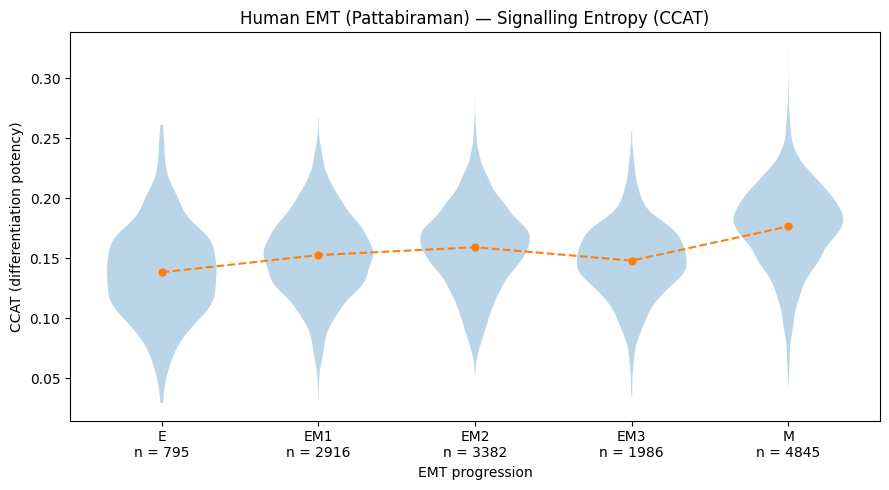

In [22]:
import numpy as np
import matplotlib.pyplot as plt


# ============================================================
# DEVELOPMENTAL ORDER
# ============================================================

sample_order = [
    "E",
    "EM1",
    "EM2",
    "EM3",
    "M"
]


# ============================================================
# CCAT VALUES FOR EACH EMT STAGE
# ============================================================

ccat_groups = [
    adata.obs.loc[
        adata.obs["Sample"] == stage,
        "CCAT"
    ].dropna().values
    for stage in sample_order
]


# ============================================================
# MEAN CCAT
# ============================================================

ccat_means = [
    np.mean(group)
    for group in ccat_groups
]


# ============================================================
# NUMBER OF CELLS
# ============================================================

cell_counts = (
    adata.obs["Sample"]
    .value_counts()
    .reindex(sample_order)
)


# ============================================================
# PLOT
# ============================================================

fig, ax = plt.subplots(figsize=(9, 5))

positions = np.arange(len(sample_order))


# ------------------------------------------------------------
# Violin plots
# ------------------------------------------------------------

ax.violinplot(
    ccat_groups,
    positions=positions,
    widths=0.7,
    showmeans=False,
    showmedians=False,
    showextrema=False
)


# ------------------------------------------------------------
# Mean trajectory
# ------------------------------------------------------------

ax.plot(
    positions,
    ccat_means,
    "o--",
    linewidth=1.5,
    markersize=5
)


# ============================================================
# X-AXIS LABELS
# ============================================================

labels = [
    f"{stage}\nn = {int(cell_counts.loc[stage])}"
    for stage in sample_order
]

ax.set_xticks(positions)

ax.set_xticklabels(labels)


# ============================================================
# LABELS / TITLE
# ============================================================

ax.set_xlabel("EMT progression")

ax.set_ylabel(
    "CCAT (differentiation potency)"
)

ax.set_title(
    "Human EMT (Pattabiraman) — Signalling Entropy (CCAT)"
)


plt.tight_layout()
plt.show()

In [23]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from itertools import combinations
from scipy.stats import ttest_ind
from statsmodels.stats.multitest import multipletests


# ============================================================
# EMT DEVELOPMENTAL ORDER
# ============================================================

sample_order = [
    "E",
    "EM1",
    "EM2",
    "EM3",
    "M"
]


# ============================================================
# PAIRWISE WELCH T-TEST
# ============================================================

ccat_results = []

for group1, group2 in combinations(sample_order, 2):

    x1 = adata.obs.loc[
        adata.obs["Sample"] == group1,
        "CCAT"
    ].dropna()

    x2 = adata.obs.loc[
        adata.obs["Sample"] == group2,
        "CCAT"
    ].dropna()

    if len(x1) == 0 or len(x2) == 0:
        continue

    statistic, pvalue = ttest_ind(
        x1,
        x2,
        equal_var=False
    )

    ccat_results.append({
        "Group1": group1,
        "Group2": group2,
        "n1": len(x1),
        "n2": len(x2),
        "t_stat": statistic,
        "p_value": pvalue
    })


ccat_results = pd.DataFrame(ccat_results)


# ============================================================
# BH FDR CORRECTION
# ============================================================

ccat_results["p_adj"] = multipletests(
    ccat_results["p_value"],
    method="fdr_bh"
)[1]


display(ccat_results)

,Group1,Group2,n1,n2,t_stat,p_value,p_adj
0,E,EM1,795,2916,-9.462283,1.596665e-20,2.280951e-20
1,E,EM2,795,3382,-14.009875,3.294969e-41,6.589938e-41
2,E,EM3,795,1986,-6.349341,3.039935e-10,3.377706e-10
3,E,M,795,4845,-26.288363,1.046766e-116,3.489220e-116
4,EM1,EM2,2916,3382,-7.520053,6.256780e-14,7.820975e-14
5,EM1,EM3,2916,1986,4.813398,1.531796e-06,1.531796e-06
6,EM1,M,2916,4845,-29.380492,1.062340e-177,5.311702e-177
7,EM2,EM3,3382,1986,12.173869,1.415303e-33,2.358839e-33
8,EM2,M,3382,4845,-22.207838,8.788665e-106,2.197166e-105
9,EM3,M,1986,4845,-33.290517,1.633576e-215,1.633576e-214


In [24]:
# ============================================================
# CREATE SYMMETRIC P-ADJ MATRIX
# ============================================================

ccat_padj = pd.DataFrame(
    np.nan,
    index=sample_order,
    columns=sample_order
)


for _, row in ccat_results.iterrows():

    group1 = row["Group1"]
    group2 = row["Group2"]
    p_adj = row["p_adj"]

    ccat_padj.loc[group1, group2] = p_adj
    ccat_padj.loc[group2, group1] = p_adj


display(ccat_padj)

,E,EM1,EM2,EM3,M
E,NaN,2.280951e-20,6.589938e-41,3.377706e-10,3.489220e-116
EM1,2.280951e-20,NaN,7.820975e-14,1.531796e-06,5.311702e-177
EM2,6.589938e-41,7.820975e-14,NaN,2.358839e-33,2.197166e-105
EM3,3.377706e-10,1.531796e-06,2.358839e-33,NaN,1.633576e-214
M,3.489220e-116,5.311702e-177,2.197166e-105,1.633576e-214,NaN


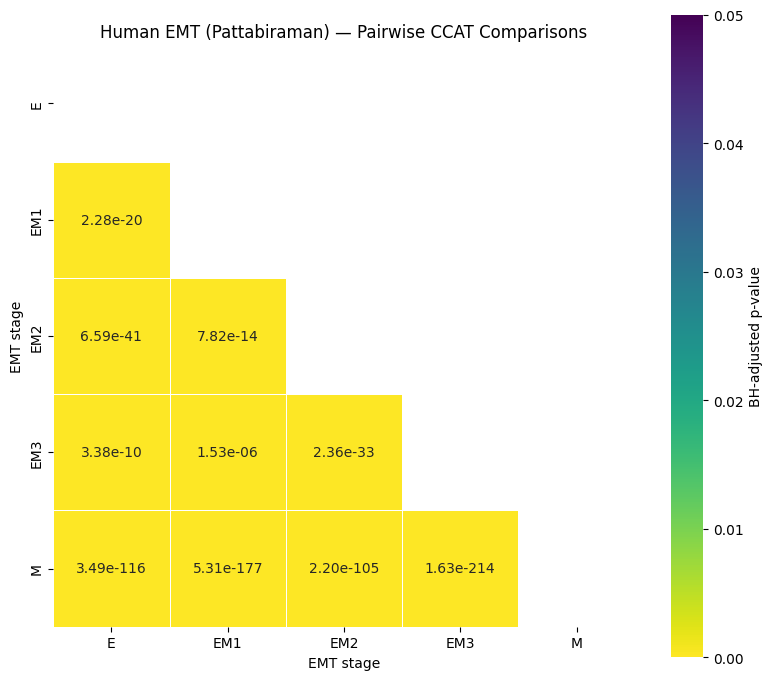

In [38]:
# ============================================================
# CCAT — PAIRWISE WELCH T-TEST HEATMAP
# ============================================================

mask = np.triu(
    np.ones_like(ccat_padj, dtype=bool)
)


plt.figure(figsize=(8, 7))

sns.heatmap(
    ccat_padj,
    mask=mask,
    annot=True,
    fmt=".2e",
    cmap="viridis_r",
    vmin=0,
    vmax=0.05,
    linewidths=0.5,
    square=True,
    cbar_kws={
        "label": "BH-adjusted p-value"
    }
)

plt.title(
    "Human EMT (Pattabiraman) — Pairwise CCAT Comparisons"
)

plt.xlabel("EMT stage")
plt.ylabel("EMT stage")

plt.tight_layout()
plt.show()

/tmp/ipykernel_873056/182101459.py:54: RuntimeWarning: divide by zero encountered in log
  P[valid] * np.log(P[valid]),
/tmp/ipykernel_873056/182101459.py:54: RuntimeWarning: invalid value encountered in multiply
  P[valid] * np.log(P[valid]),


count    13924.000000
mean         7.789248
std          0.276038
min          5.851025
25%          7.691083
50%          7.839900
75%          7.965635
max          8.313123
Name: Shannon_entropy, dtype: float64


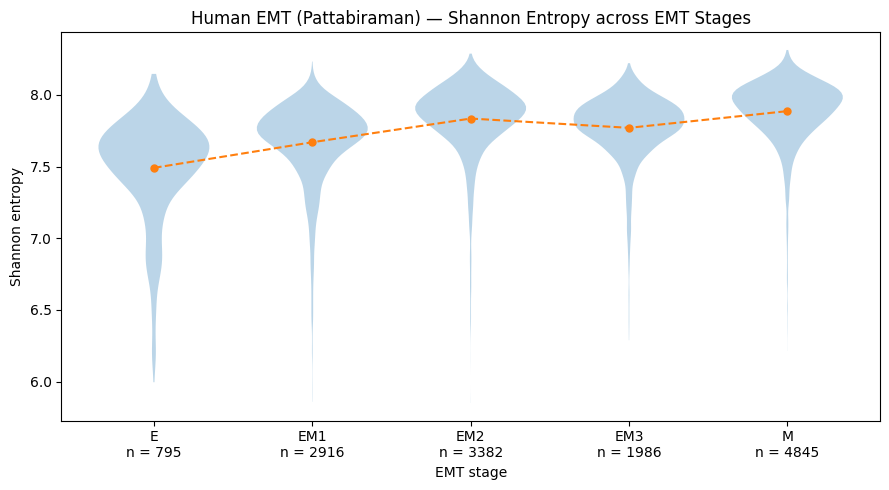

In [26]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# EMT STAGE ORDER
# ============================================================

sample_order = [
    "E",
    "EM1",
    "EM2",
    "EM3",
    "M"
]


# ============================================================
# CALCULATE SHANNON ENTROPY PER CELL
# ============================================================

X = adata.X

if hasattr(X, "toarray"):
    X = X.toarray()

X = np.asarray(X, dtype=np.float64)


# ------------------------------------------------------------
# Convert expression to probabilities within each cell
# ------------------------------------------------------------

row_sums = X.sum(axis=1)

# Avoid division by zero
valid = row_sums > 0

P = np.zeros_like(X)

P[valid] = X[valid] / row_sums[valid, None]


# ------------------------------------------------------------
# Shannon entropy
# ------------------------------------------------------------

shannon_entropy = np.zeros(X.shape[0])

shannon_entropy[valid] = -np.sum(
    np.where(
        P[valid] > 0,
        P[valid] * np.log(P[valid]),
        0
    ),
    axis=1
)


# Store in AnnData
adata.obs["Shannon_entropy"] = shannon_entropy


print(adata.obs["Shannon_entropy"].describe())


# ============================================================
# GET ENTROPY DISTRIBUTIONS BY EMT STAGE
# ============================================================

entropy_groups = [
    adata.obs.loc[
        adata.obs["Sample"] == stage,
        "Shannon_entropy"
    ].dropna().values
    for stage in sample_order
]


# ============================================================
# MEAN SHANNON ENTROPY
# ============================================================

entropy_means = [
    np.mean(group)
    for group in entropy_groups
]


# ============================================================
# NUMBER OF CELLS
# ============================================================

cell_counts = (
    adata.obs["Sample"]
    .value_counts()
    .reindex(sample_order)
)


# ============================================================
# PLOT
# ============================================================

fig, ax = plt.subplots(figsize=(9, 5))

positions = np.arange(len(sample_order))


# ------------------------------------------------------------
# Violin plots
# ------------------------------------------------------------

ax.violinplot(
    entropy_groups,
    positions=positions,
    widths=0.7,
    showmeans=False,
    showmedians=False,
    showextrema=False
)


# ------------------------------------------------------------
# Mean trajectory
# ------------------------------------------------------------

ax.plot(
    positions,
    entropy_means,
    "o--",
    linewidth=1.5,
    markersize=5
)


# ------------------------------------------------------------
# X-axis labels + cell counts
# ------------------------------------------------------------

ax.set_xticks(positions)

ax.set_xticklabels([
    f"{stage}\nn = {int(cell_counts.loc[stage])}"
    for stage in sample_order
])


# ============================================================
# FORMATTING
# ============================================================

ax.set_xlabel("EMT stage")

ax.set_ylabel("Shannon entropy")

ax.set_title(
    "Human EMT (Pattabiraman) — Shannon Entropy across EMT Stages"
)

plt.tight_layout()
plt.show()

,Group1,Group2,n1,n2,t_stat,p_value,p_adj
0,E,EM1,795,2916,-13.045070,3.024353e-36,3.780441e-36
1,E,EM2,795,3382,-25.805010,1.698100e-112,4.245249e-112
2,E,EM3,795,1986,-20.443546,1.068453e-78,2.136906e-78
3,E,M,795,4845,-30.360224,6.098145e-140,3.049073e-139
4,EM1,EM2,2916,3382,-24.316937,1.825754e-124,6.085845e-124
5,EM1,EM3,2916,1986,-13.548661,4.616337e-41,6.594767e-41
6,EM1,M,2916,4845,-35.017365,1.161366e-240,1.161366e-239
7,EM2,EM3,3382,1986,9.662934,7.143840e-22,7.143840e-22
8,EM2,M,3382,4845,-9.707503,3.898654e-22,4.331838e-22
9,EM3,M,1986,4845,-19.110305,1.321512e-77,2.202520e-77


,E,EM1,EM2,EM3,M
E,NaN,3.780441e-36,4.245249e-112,2.136906e-78,3.049073e-139
EM1,3.780441e-36,NaN,6.085845e-124,6.594767e-41,1.161366e-239
EM2,4.245249e-112,6.085845e-124,NaN,7.143840e-22,4.331838e-22
EM3,2.136906e-78,6.594767e-41,7.143840e-22,NaN,2.202520e-77
M,3.049073e-139,1.161366e-239,4.331838e-22,2.202520e-77,NaN


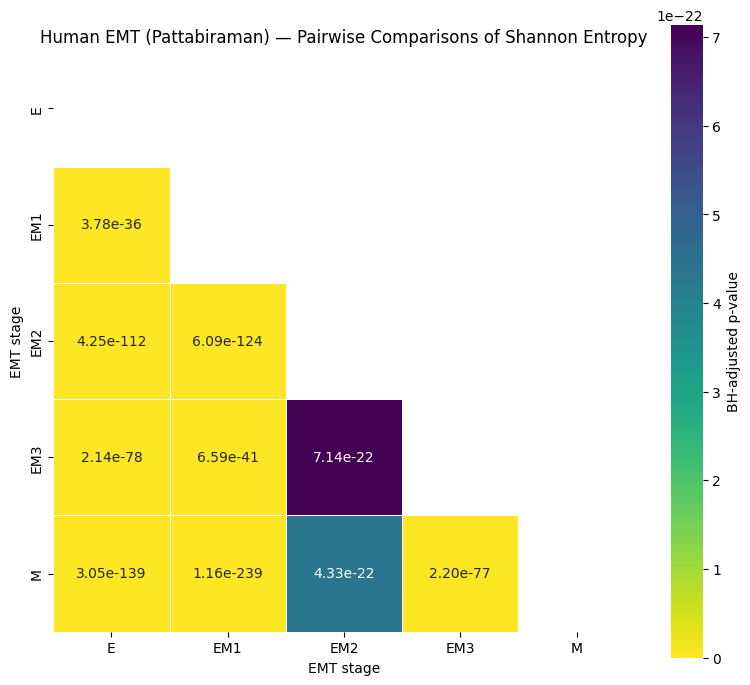

In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from itertools import combinations
from scipy.stats import ttest_ind
from statsmodels.stats.multitest import multipletests


# ============================================================
# EMT STAGE ORDER
# ============================================================

sample_order = [
    "E",
    "EM1",
    "EM2",
    "EM3",
    "M"
]


# ============================================================
# PAIRWISE WELCH T-TESTS
# ============================================================

entropy_results = []

for group1, group2 in combinations(sample_order, 2):

    x1 = adata.obs.loc[
        adata.obs["Sample"] == group1,
        "Shannon_entropy"
    ].dropna()

    x2 = adata.obs.loc[
        adata.obs["Sample"] == group2,
        "Shannon_entropy"
    ].dropna()

    if len(x1) == 0 or len(x2) == 0:
        continue

    statistic, pvalue = ttest_ind(
        x1,
        x2,
        equal_var=False
    )

    entropy_results.append({
        "Group1": group1,
        "Group2": group2,
        "n1": len(x1),
        "n2": len(x2),
        "t_stat": statistic,
        "p_value": pvalue
    })


entropy_results = pd.DataFrame(entropy_results)


# ============================================================
# BH FDR CORRECTION
# ============================================================

entropy_results["p_adj"] = multipletests(
    entropy_results["p_value"],
    method="fdr_bh"
)[1]


display(entropy_results)


# ============================================================
# CREATE SYMMETRIC P-ADJ MATRIX
# ============================================================

entropy_padj = pd.DataFrame(
    np.nan,
    index=sample_order,
    columns=sample_order
)


for _, row in entropy_results.iterrows():

    group1 = row["Group1"]
    group2 = row["Group2"]

    entropy_padj.loc[group1, group2] = row["p_adj"]
    entropy_padj.loc[group2, group1] = row["p_adj"]


display(entropy_padj)


# ============================================================
# SHANNON ENTROPY — PAIRWISE HEATMAP
# ============================================================

mask = np.triu(
    np.ones_like(entropy_padj, dtype=bool)
)


plt.figure(figsize=(8, 7))

sns.heatmap(
    entropy_padj,
    mask=mask,
    annot=True,
    fmt=".2e",
    cmap="viridis_r",
    linewidths=0.5,
    square=True,
    cbar_kws={
        "label": "BH-adjusted p-value"
    }
)

plt.title(
    "Human EMT (Pattabiraman) — Pairwise Comparisons of Shannon Entropy"
)

plt.xlabel("EMT stage")
plt.ylabel("EMT stage")

plt.tight_layout()
plt.show()

In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr

In [29]:
import pandas as pd
import numpy as np

id_df = pd.read_excel("/home/csb/Saloni/SCENT/data/ID/Pattabiraman_ID_local.xlsx")

print(id_df.head())
print(id_df.columns)

                     Unnamed: 0        ID
0  AAACCAGGTGCGATAAACTTTAGG-1-0  0.420520
1  AAACCGGTCCTGCCAGACTTTAGG-1-0  0.582540
2  AAACCGGTCGAACCGAACTTTAGG-1-0  0.157976
3  AAAGCCTAGGCAAGTTACTTTAGG-1-0  0.187279
4  AAAGCCTAGTTGGATAACTTTAGG-1-0  0.402510
Index(['Unnamed: 0', 'ID'], dtype='object')


In [30]:
id_df = id_df.set_index(id_df.columns[0])

id_df.index = id_df.index.astype(str)

In [31]:
adata.obs["ID"] = id_df["ID"].reindex(adata.obs_names)

In [32]:
print(adata.obs['CCAT'])

AAACCAGGTGCGATAAACTTTAGG-1-0    0.197505
AAACCGGTCCTGCCAGACTTTAGG-1-0    0.108303
AAACCGGTCGAACCGAACTTTAGG-1-0    0.050241
AAAGCCTAGGCAAGTTACTTTAGG-1-0    0.135317
AAAGCCTAGTTGGATAACTTTAGG-1-0    0.141858
                                  ...   
TTTGCTCTCAGGCCTTAGTAGGCT-1-4    0.116315
TTTGCTCTCGGTAAGTAGTAGGCT-1-4    0.175499
TTTGGACGTCAATACCAGTAGGCT-1-4    0.169515
TTTGGCGGTCCAATACAGTAGGCT-1-4    0.144106
TTTGTGAGTTTGCTCCAGTAGGCT-1-4    0.170791
Name: CCAT, Length: 13924, dtype: float32


In [33]:
print(adata.obs[["ID", "Sample"]].head())

print("Cells in adata:", adata.n_obs)
print("Cells with ID:", adata.obs["ID"].notna().sum())
print("Missing ID:", adata.obs["ID"].isna().sum())

                                    ID Sample
AAACCAGGTGCGATAAACTTTAGG-1-0  0.420520      E
AAACCGGTCCTGCCAGACTTTAGG-1-0  0.582540      E
AAACCGGTCGAACCGAACTTTAGG-1-0  0.157976      E
AAAGCCTAGGCAAGTTACTTTAGG-1-0  0.187279      E
AAAGCCTAGTTGGATAACTTTAGG-1-0  0.402510      E
Cells in adata: 13924
Cells with ID: 13924
Missing ID: 0


In [34]:
from scipy.stats import pearsonr, spearmanr
import matplotlib.pyplot as plt

plot_data = adata.obs[
    ["ID", "CCAT", "Sample"]
].dropna()

# ============================================================
# CORRELATION
# ============================================================

pearson_r, pearson_p = pearsonr(
    plot_data["ID"],
    plot_data["CCAT"]
)

spearman_r, spearman_p = spearmanr(
    plot_data["ID"],
    plot_data["CCAT"]
)

print(f"Pearson r = {pearson_r:.4f}, p = {pearson_p:.4e}")
print(f"Spearman rho = {spearman_r:.4f}, p = {spearman_p:.4e}")

Pearson r = 0.5181, p = 0.0000e+00
Spearman rho = 0.5278, p = 0.0000e+00
